# Graph to timeseries generation strategies

We generate timeseries from univariate and multivariate graphs, by walking through the graph and appending values to our sequence.

There are two main components or strategies needed for timeseries generation:

## Selection of next node in graph:

### - *Random Next Node Selection*:

First strategy and the simplest strategy we can have here is just randomly selecting next node from the pool of all appropriate nodes. (In univariate graphs, every node is appropriate, but in multivariate graph, only appropriate nodes are ones that originate from the univariate graph we are currently on)

### - *Random Next Node Selection from Neighbors Across Graphs* and *Random Next Node Selection from Neighbors of the First Graph*:

These strategies are very similar to one another. If we have univariate graph it does not matter which one we choose. Each of them will return random neighbour of the last node we analyzed.

If we have a multivariate graph, the strategy from class  StrategySelectNextNodeRandomlyFromNeighboursFromFirstGraph will only walkthrough the first graph, while giving back neighbours of the last node we analyzed from each of the univariate graph in this multivariate one. StrategySelectNextNodeRandomlyFromNeighboursAcrossGraphs strategy on the other hand will continuously switch between univariate graphs and will not just remain on the first one. With this strategy we can also set, how long does the programme spend walking through each graph.

### - *Random Next Node Selection with Restart*:

This strategy will choose next node randomly, just like StrategySelectNextNodeRandomly, but there will always be 15% chance that it will jump back to the first node of the graph.

### - *Random Next Node Selection Based on Degree*:

This strategy will choose next node randomly from its neighbours based on degree/weight of the connection between the two.

## Selection of next value in the selected node:

Some strategies of graph generation, result in a single node having multiple values instead of just one. If nodes have only one value, you can just select any strategy that isn't specified to be for a certain type of graph.

### - *Random Next Value in Node* and *Random Next Value in Node for Sliding Window*:

These two methods will choose next value from available ones randomly.

### - *Round Robin Next Value in Node* and *Round Robin Next Value in Node for Sliding Window*:

These two methods will choose next value sequentially, in orther of their appearance in original graph. If last one is reached, it will start again at the beginning.

### - *Ordinal Partition Next Value in Node*:

This strategy is designed specifically for the ordinal partition graphs. As their nodes do not store original values, histogram of values is made at the beginning, which is later on used for value selection.

## Additional strategies:

Along with these strategies we can also tell how many values we want to skip, between appending another one. We must also tell how long do we want our timeseries to be.

## Examples:

Here are some examples of graphs and timeseries generated from them:

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7ff762b6a780>
Number of dimensions: 1; total windows: 1


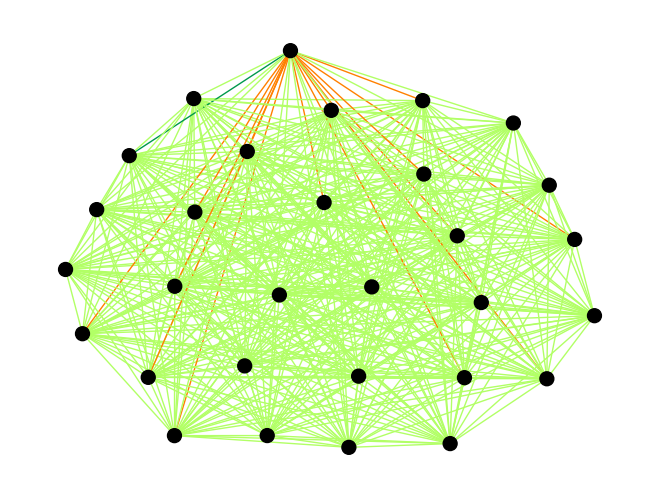

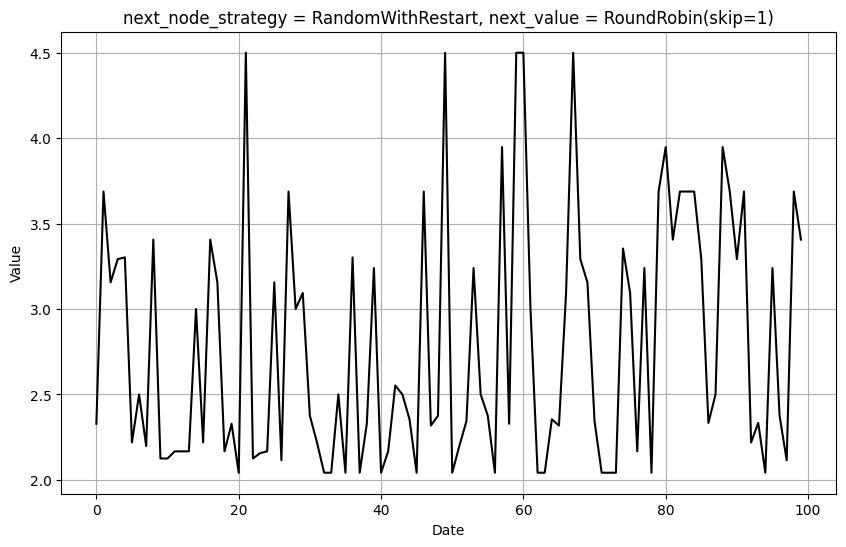

In [16]:
import os, sys
sys.path.append("/var/scratch/sdu/ts2g2")
import warnings
warnings.filterwarnings("ignore")

import utils
from pipeline import T2G2Pipeline
from visualization import draw_g, draw_sequences
from strategies.view import get_view_strategy
from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder
from strategies.merge.strategy_linking_graph import StrategyLinkingGraphByValueWithinRange
from strategies.merge import get_link_nodes_strategy_builder
from strategies.g2ts import (
    get_g2ts_strategy,
    StrategySelectNextNodeRandomWithRestart,
    StrategyNextValueInNodeRoundRobin,
)

# --- data ---
amazon_path = os.path.join(os.getcwd(), "amazon", "AMZN.csv")
ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

# --- view strategy: slice 60:90 ---
view_strategy = get_view_strategy("slice")(start_index=60, end_index=90)

# --- ts->graph: Natural Visibility with limit=1 ---
builder_cls = get_ts2g_strategy_builder(method="natural_visibility")
ts2g_strategy = builder_cls().with_limit(1).get_strategy()

# --- link-nodes strategy: by value within range=2 + seasonalities(15) ---
link_nodes_builder = get_link_nodes_strategy_builder()
link_nodes_strategy = (
    link_nodes_builder()
    .by_value(StrategyLinkingGraphByValueWithinRange(2))
    .seasonalities(15)
)

# --- pipeline ---
pipeline = T2G2Pipeline()
(
    pipeline.load_timeseries(ts_data)
            .viewing(view_strategy)
            .to_graph(ts2g_strategy)
            .add_edge(0, 2)
            .add_edge(13, 21, weight=17)
            .link_nodes_within_graphs(link_nodes_strategy)
)

# --- plot graph ---
G = pipeline.get_Graph()
draw_g(G)

# --- g2ts strategy ---
g2ts_cls = get_g2ts_strategy("plain")
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomWithRestart())
    .next_value_strategy(StrategyNextValueInNodeRoundRobin().skip_every_x_steps(1))
    .ts_length(100)
)

# --- convert back to sequence ---
sequences = pipeline.to_timeseries(g2ts).sequences

# --- plot sequence ---
draw_sequences(
    sequences,
    node_strategy_name="RandomWithRestart",
    value_strategy_name="RoundRobin(skip=1)",
)

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7ff606bf7bc0>
Number of dimensions: 1; total windows: 1
Applying viewing strategy: <strategies.view.views.FixedOverlapWindow object at 0x7ff60c0c9df0>
Number of dimensions: 1; total windows: 56


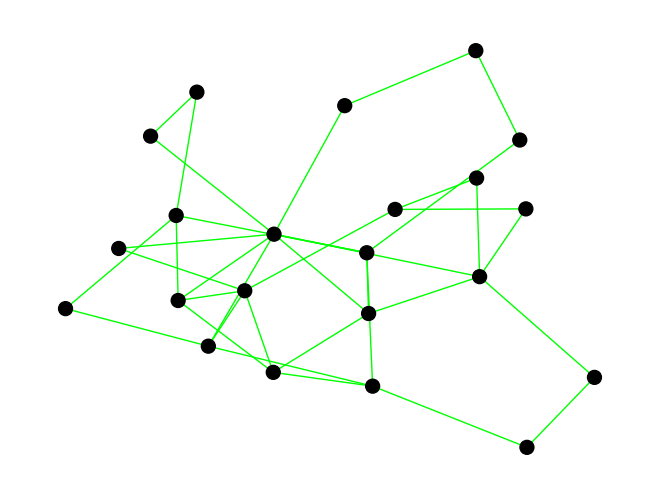

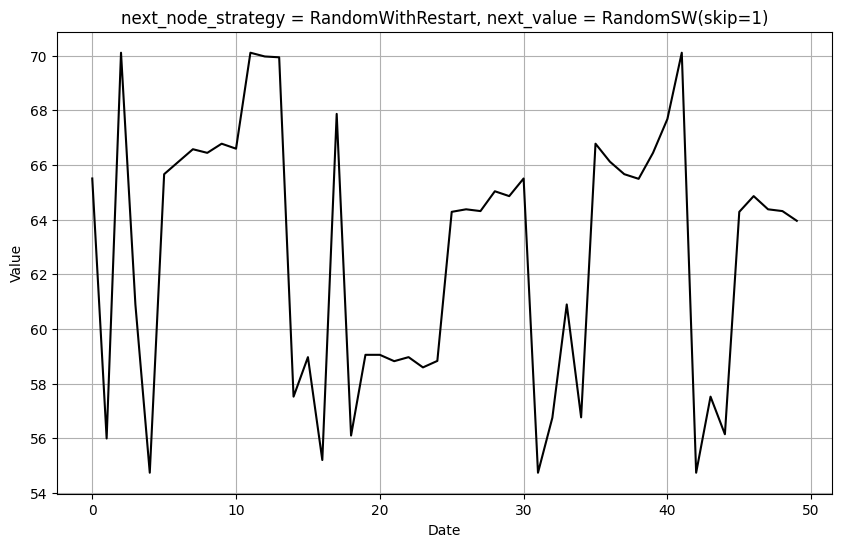

In [17]:
import os, sys
sys.path.append("/var/scratch/sdu/ts2g2")
import warnings
warnings.filterwarnings("ignore")

import utils
from pipeline import T2G2Pipeline
from visualization import draw_g, draw_sequences

from strategies.view import get_view_strategy
from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder
from strategies.merge import get_link_multigraph_strategy_builder

from strategies.g2ts import (
    get_g2ts_strategy,
    StrategySelectNextNodeRandomWithRestart,
    StrategyNextValueInNodeRandomForSlidingWindow,
)

# data
apple_path = os.path.join(os.getcwd(), "apple", "APPLE.csv")
ts_data = utils.CsvFile(apple_path, "Close").from_csv()

# viewing: segmentation(60:120) -> sliding window (5, step=1)
view_seg = get_view_strategy("slice")(start_index=60, end_index=120)
view_sw  = get_view_strategy("sliding_window")(window_size=5, step_size=1)

# ts->graph: Natural Visibility
ts2g_builder  = get_ts2g_strategy_builder(method="natural_visibility")
ts2g_strategy = ts2g_builder().get_strategy()

# link multi-graphs: sliding_window linking
merge_builder = get_link_multigraph_strategy_builder()
link_strategy = merge_builder().sliding_window()

# pipeline
pipeline2 = T2G2Pipeline()
(
    pipeline2.load_timeseries(ts_data)
             .viewing(view_seg)
             .viewing(view_sw)
             .to_graph(ts2g_strategy)
             .link_graphs(link_strategy)
             .combine_identical_subgraphs()
)

# plot fused graph
G2 = pipeline2.get_Graph()
draw_g(G2)

# g2ts: sliding-window reconstruction
g2ts_cls = get_g2ts_strategy("sliding_window")
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomWithRestart())
    .next_value_strategy(StrategyNextValueInNodeRandomForSlidingWindow().skip_every_x_steps(1))
    .ts_length(50)
)

sequences2 = pipeline2.to_timeseries(g2ts).sequences
draw_sequences(sequences2, node_strategy_name="RandomWithRestart", value_strategy_name="RandomSW(skip=1)")

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7ff60ee4b320>
Number of dimensions: 1; total windows: 1


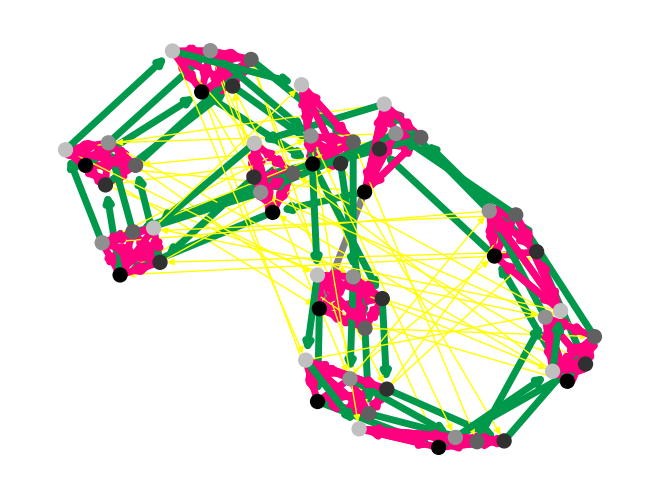

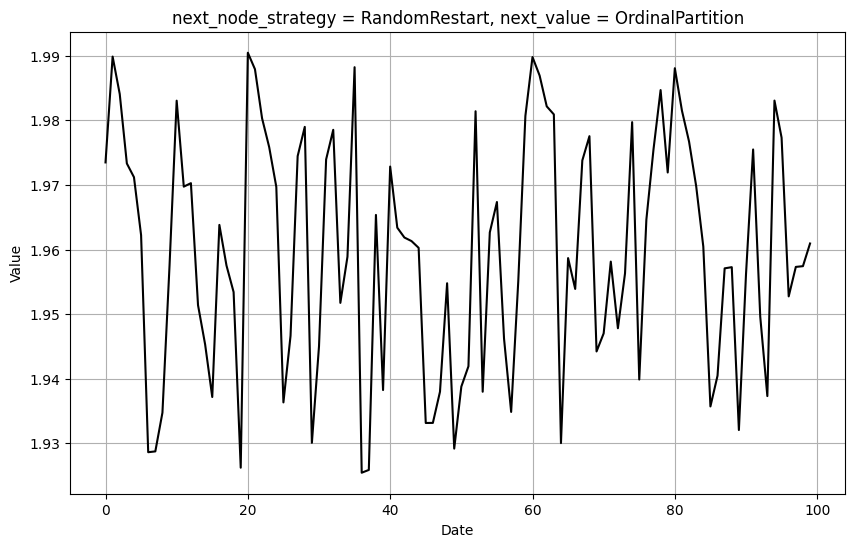

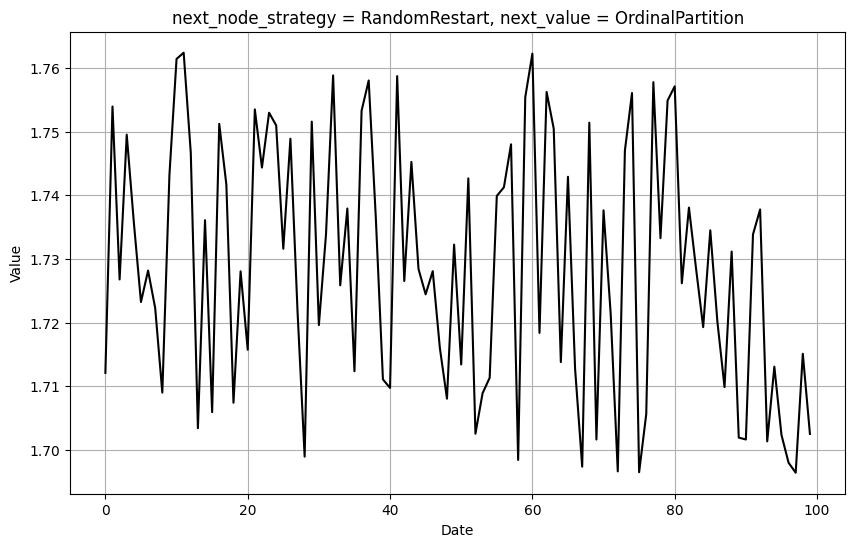

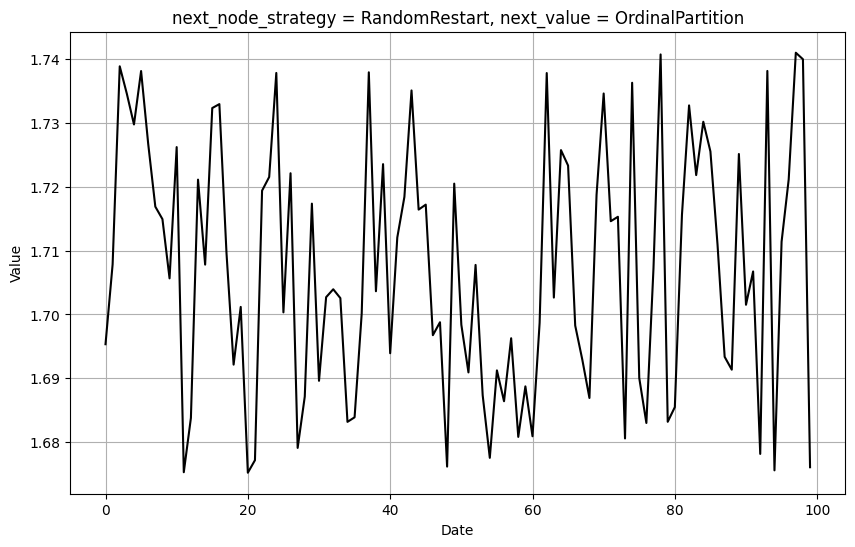

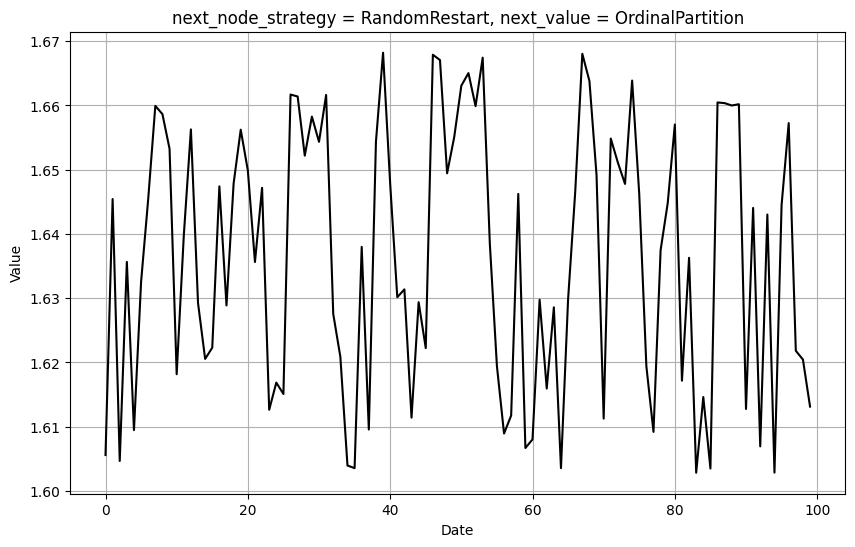

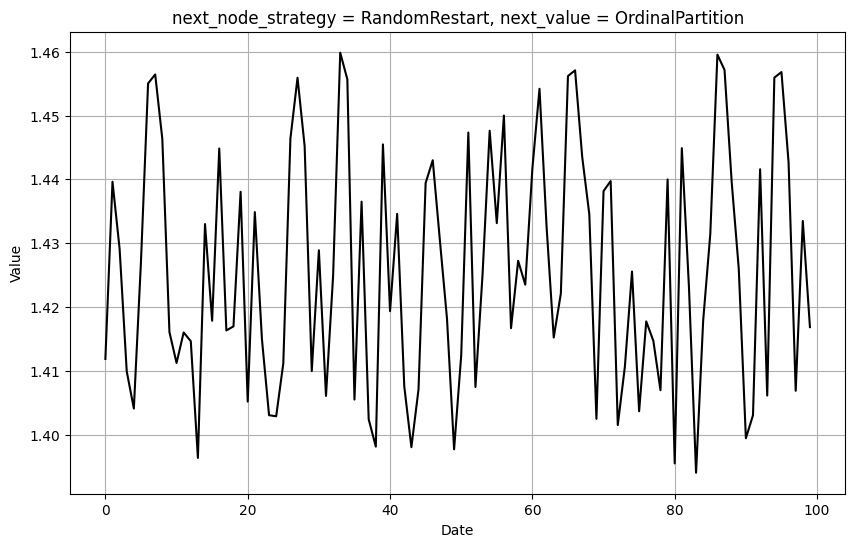

In [18]:
import os, sys
sys.path.append("/var/scratch/sdu/ts2g2")
import warnings
warnings.filterwarnings("ignore")

import utils
from pipeline import T2G2Pipeline
from visualization import draw_g, draw_sequences

from strategies.view import get_view_strategy
from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder
from strategies.merge import get_link_multigraph_strategy_builder, get_link_nodes_strategy_builder
from strategies.merge.strategy_linking_graph import StrategyLinkingGraphByValueWithinRange
from strategies.g2ts import (
    get_g2ts_strategy,
    StrategySelectNextNodeRandomWithRestart,
    StrategyNextValueInNodeOrdinalPartition,
)

# data
amazon_path = os.path.join(os.getcwd(), "amazon", "AMZN.csv")
ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

# five segmentation views
views = [
    get_view_strategy("slice")(start_index=60,   end_index=120),
    get_view_strategy("slice")(start_index=120,  end_index=180),
    get_view_strategy("slice")(start_index=500,  end_index=560),
    get_view_strategy("slice")(start_index=700,  end_index=760),
    get_view_strategy("slice")(start_index=1000, end_index=1060),
]

# ts->graph: Ordinal Partition (w=10, tau=5)
ts2g_builder  = get_ts2g_strategy_builder(method="ordinal")
ts2g_strategy = ts2g_builder(10, 5).get_strategy()

# link multi-graphs: time_cooccurrence
merge_builder = get_link_multigraph_strategy_builder()
link_multi    = merge_builder().time_cooccurrence()

# link nodes within subgraph: seasonalities(4)
link_nodes_builder = get_link_nodes_strategy_builder()
link_nodes         = link_nodes_builder().seasonalities(4)

# pipeline
pipeline3 = T2G2Pipeline().load_timeseries(ts_data)
for i, v in enumerate(views):
    if i == 0:
        pipeline3 = pipeline3.viewing(v)
    else:
        pipeline3 = pipeline3.add_view(v)

(
    pipeline3.to_histogram(15)
             .to_graph(ts2g_strategy)
             .link_graphs(link_multi)
             .link_nodes_within_graphs(link_nodes)
)

# manually add edge (like old add_edge(0,2))
G3 = pipeline3.get_Graph()
nodes = list(G3.nodes())
if len(nodes) > 2:
    G3.add_edge(nodes[0], nodes[2])

# plot graph
draw_g(G3)

# g2ts: ordinal partition reconstruction
g2ts_cls = get_g2ts_strategy("ordinal_partition")
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomWithRestart())
    .next_value_strategy(StrategyNextValueInNodeOrdinalPartition())
    .ts_length(100)
)

sequences3 = pipeline3.to_timeseries(g2ts).sequences
draw_sequences(sequences3, node_strategy_name="RandomRestart", value_strategy_name="OrdinalPartition")